# Теория вероятностей. Домашнее задание
### Выполнила: Кудрявцева Екатерина

## 2. Симуляции в Python

### Задание 2.1. Нормальная выборка

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import math

np.random.seed(42)

Выборка: 5000 значений со средним 40 и стандартным отклонением 8

In [2]:
mu, sigma = 40, 8
sample = np.random.normal(mu, sigma, size=5000)

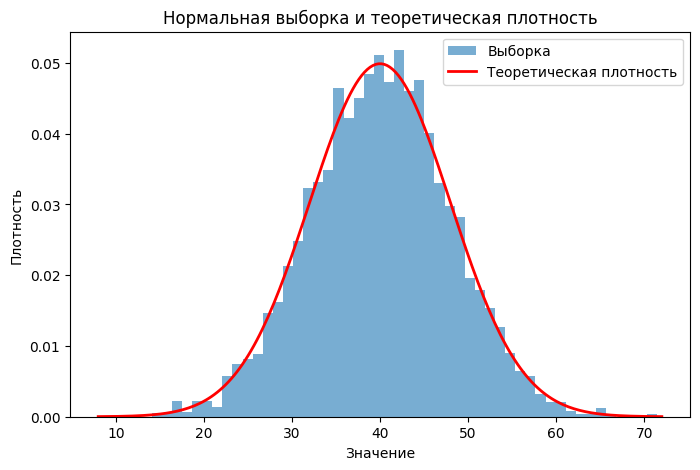

In [3]:
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)

plt.figure(figsize=(8, 5))
plt.hist(sample, bins=50, density=True, alpha=0.6, label='Выборка')
plt.plot(x, stats.norm.pdf(x, mu, sigma), 'r', lw=2, label='Теоретическая плотность')
plt.xlabel('Значение')
plt.ylabel('Плотность')
plt.title('Нормальная выборка и теоретическая плотность')
plt.legend()
plt.show()

In [4]:
print(f'Среднее выборки: задано {mu}, по выборке {sample.mean():.2f}')
print(f'Ст. отклонение выборки: задано {sigma}, по выборке {sample.std():.2f}')

Среднее выборки: задано 40, по выборке 40.04
Ст. отклонение выборки: задано 8, по выборке 7.97


In [5]:
print(f'Стандартная ошибка: {(8 / math.sqrt(5000)):.2f}')

Стандартная ошибка: 0.11


Видно, что график сгенерированного распределения очень похож на теоретическую колоколообразную кривую. Среднее и стандартное отклонение выборки очень близки к заданным.    
Расхождение объясняется случайностью конечной выборки: стандартная ошибка среднего 0.11, так что отклонение выборочного среднего от 40 в рамках десятых долей единицы ожидаемо

### Задание 2.2. Биномиальная выборка

Выборка: 5000 значений биномиального распределения с n = 1000 и p = 0.04

In [6]:
n, p = 1000, 0.04
sample_bin = np.random.binomial(n, p, size=5000)

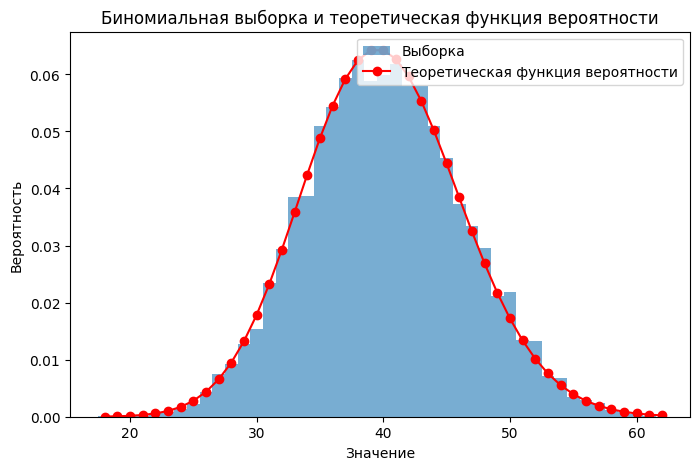

In [7]:
k = np.arange(sample_bin.min(), sample_bin.max() + 1)

plt.figure(figsize=(8, 5))
plt.hist(sample_bin, bins=k - 0.5, density=True, alpha=0.6, label='Выборка')
plt.plot(k, stats.binom.pmf(k, n, p), 'ro-', label='Теоретическая функция вероятности')
plt.xlabel('Значение')
plt.ylabel('Вероятность')
plt.title('Биномиальная выборка и теоретическая функция вероятности')
plt.legend()
plt.show()

In [8]:
mean_theory = n * p
std_theory = math.sqrt(n * p * (1 - p))

print(f'Среднее выборки: теоретическое {mean_theory:.2f}, по выборке {sample_bin.mean():.2f}')
print(f'Ст. отклонение выборки: теоретическое {std_theory:.2f}, по выборке {sample_bin.std():.2f}')

Среднее выборки: теоретическое 40.00, по выборке 40.14
Ст. отклонение выборки: теоретическое 6.20, по выборке 6.25


Видно, что точки теоретической функции вероятности попадают в вершины столбиков гистограммы, то есть симуляция согласуется с формулой. Среднее и стандартное отклонение выборки также очень близки к теоретическим значениям $np=40$ и $√(np(1−p))=6.20$

### Задание 2.3. ЦПТ на экспоненциальном распределении

Выборки: 5000 раз по 500 значений экспоненциального распределения со ст. отклонением (средним) 1500, для каждой считаю среднее

In [9]:
scale = 1500
n_per_sample = 500
n_repeats = 5000

means = [
    np.random.exponential(scale=scale, size=n_per_sample).mean()
    for i in range(n_repeats)
]

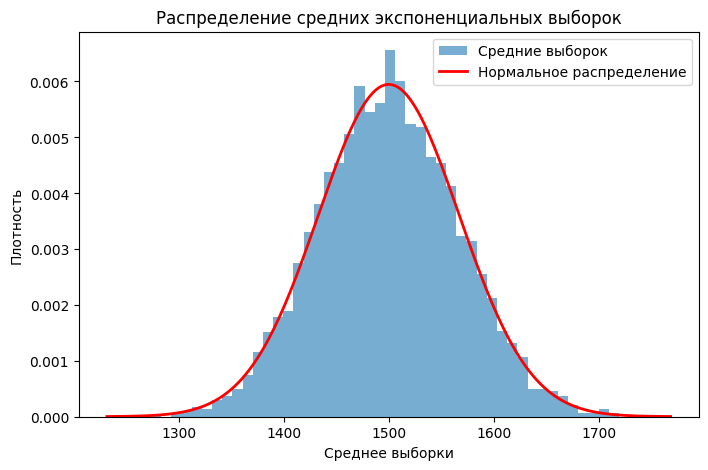

In [10]:
mu_means = scale
sigma_means = scale / math.sqrt(n_per_sample)
x = np.linspace(mu_means - 4*sigma_means, mu_means + 4*sigma_means, 200)

plt.figure(figsize=(8, 5))
plt.hist(means, bins=50, density=True, alpha=0.6, label='Средние выборок')
plt.plot(x, stats.norm.pdf(x, mu_means, sigma_means), 'r', lw=2, label='Нормальное распределение')
plt.xlabel('Среднее выборки')
plt.ylabel('Плотность')
plt.title('Распределение средних экспоненциальных выборок')
plt.legend()
plt.show()

In [11]:
print(f'Среднее средних: теоретическое {mu_means:.2f}, по симуляции {np.mean(means):.2f}')
print(f'Ст. отклонение средних: теоретическое {sigma_means:.2f}, по симуляции {np.std(means):.2f}')

Среднее средних: теоретическое 1500.00, по симуляции 1499.91
Ст. отклонение средних: теоретическое 67.08, по симуляции 66.62


Гистограмма средних имеет форму симметричного колокола и почти совпадает с нормальной кривой, хотя само экспоненциальное распределение скошено вправо. Полученные значения среднего и ст. отклонения также близки к теоретическим.
Это получается из-за центральной предельной теоремы: среднее большого числа независимых значений стремится к нормальному распределению

## Кейс про кнопку

Группы:
- Старая кнопка: 5000 соискателей, 155 отликов, конверсия 3.1%
- Новая кнопка: 5000 соискателей, 170 откликов, конверсия 3.4%.   

Разница 0,3 п.п.

## Задание 3.1

Стандартная ошибка конверсии для каждой группы: $SE=\sqrt{p(1-p)/n}$

In [12]:
n_old, resp_old = 5000, 155
n_new, resp_new = 5000, 170

p_old = resp_old / n_old
p_new = resp_new / n_new

se_old = math.sqrt(p_old * (1 - p_old) / n_old)
se_new = math.sqrt(p_new * (1 - p_new) / n_new)

print(f'Старая кнопка: конверсия {p_old*100:.1f}%, стандартная ошибка {se_old*100:.2f} п.п.')
print(f'Новая кнопка: конверсия {p_new*100:.1f}%, стандартная ошибка {se_new*100:.2f} п.п.')

Старая кнопка: конверсия 3.1%, стандартная ошибка 0.25 п.п.
Новая кнопка: конверсия 3.4%, стандартная ошибка 0.26 п.п.


Группы независимы, поэтому дисперсии складываются: $SE_{разн}=\sqrt{SE_{old}^2+SE_{new}^2}$

In [13]:
diff = p_new - p_old
se_diff = math.sqrt(se_old**2 + se_new**2)

print(f'Разница конверсий: {diff*100:.2f} п.п.')
print(f'Стандартная ошибка разницы: {se_diff*100:.2f} п.п.')
print(f'Разница cтандартных ошибок: {diff / se_diff:.2f}')

Разница конверсий: 0.30 п.п.
Стандартная ошибка разницы: 0.35 п.п.
Разница cтандартных ошибок: 0.85


Ошибка оценки конверсии в каждой группе около 0.25 п.п., почти равна самой разнице в 0.3 п.п. Стандартная ошибка разницы ещё больше, 0.35 п.п., а разница составляет лишь 0.85 такой ошибки.    
Предварительный вывод: разница 0.3 п.п. меньше обычного случайного разброса, поэтому по этим данным нельзя утверждать, что новая кнопка улучшила конверсию, это может быть и случайность

## Задание 3.2

Предполагаем, что кнопка ни на что не влияет, и берем одну общую конверсию для обеих групп: доля откликов среди всех 10000 соискателей

In [14]:
p_common = (resp_old + resp_new) / (n_old + n_new)
print(f'Общая конверсия: {p_common*100:.2f}%')

Общая конверсия: 3.25%


Моделируем 10000 раз две группы по 5000 соискателей с общей конверсией и считаем разницу их конверсий

In [15]:
n_sim = 10000

resp_old_sim = np.random.binomial(n_old, p_common, size=n_sim)
resp_new_sim = np.random.binomial(n_new, p_common, size=n_sim)

diffs = resp_new_sim / n_new - resp_old_sim / n_old

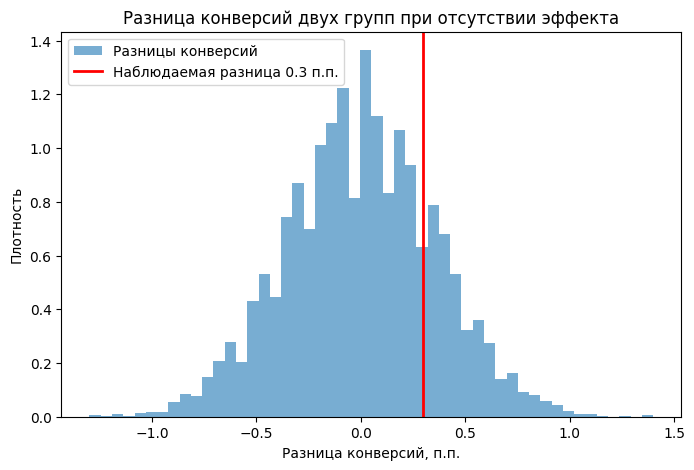

In [16]:
plt.figure(figsize=(8, 5))
plt.hist(diffs * 100, bins=50, density=True, alpha=0.6, label='Разницы конверсий')
plt.axvline(diff * 100, color='r', lw=2, label='Наблюдаемая разница 0.3 п.п.')
plt.xlabel('Разница конверсий, п.п.')
plt.ylabel('Плотность')
plt.title('Разница конверсий двух групп при отсутствии эффекта')
plt.legend()
plt.show()

In [17]:
share = np.mean(diffs >= diff - 1e-9)

print(f'Среднее разниц: {diffs.mean()*100:.3f} п.п.')
print(f'Ст. отклонение разниц: {diffs.std()*100:.2f} п.п.')
print(f'Доля симуляций с разницей 0.3 п.п. или больше: {share:.3f}')

Среднее разниц: 0.002 п.п.
Ст. отклонение разниц: 0.36 п.п.
Доля симуляций с разницей 0.3 п.п. или больше: 0.213


Видно, что при отсутствии эффекта разница конверсий колеблется вокруг нуля, а наблюдаемые 0.3 п.п. лежат внутри обычного разброса. Разница 0.3 п.п. или больше получается случайно примерно в каждой пятой симуляции, то есть в этом эксперименте это не редкость.   
**Вывод:** скорее это шум, а не эффект. Данных недостаточно, чтобы утверждать, что новая кнопка улучшила конверсию

## Задание 3.3. Выбросы во времени сессий

Время сессий за день, в минутах: 3, 4, 4, 5, 5, 6, 6, 7, 8, 52

In [18]:
sessions = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])  

Правило трёх сигм.  
Выбросом считаю значения, которые выходят за пределы среднее +- 3 сигмы

In [19]:
m = sessions.mean()
s = sessions.std(ddof=1)
lower_3s = m - 3 * s
upper_3s = m + 3 * s

print(f'Среднее {m:.2f}, ст. отклонение {s:.2f}')
print(f'Границы: от {lower_3s:.2f} до {upper_3s:.2f}')
print('Выбросы:', sessions[(sessions < lower_3s) + (sessions > upper_3s)])

Среднее 10.00, ст. отклонение 14.83
Границы: от -34.50 до 54.50
Выбросы: []


Перцентили (правило Тьюки).  
Выбросом считаю значения за пределами (25-й перцентиль − 1.5 × IQR) и (75-й перцентиль + 1.5 × IQR), где IQR = 75-й − 25-й перцентиль

In [20]:
p25, p75 = np.percentile(sessions, [25, 75])
iqr = p75 - p25
lower_pct = p25 - 1.5 * iqr
upper_pct = p75 + 1.5 * iqr

print(f'25-й перцентиль {p25:.2f}, 75-й перцентиль {p75:.2f}')
print(f'Границы: от {lower_pct:.2f} до {upper_pct:.2f}')
print('Выбросы:', sessions[(sessions < lower_pct) + (sessions > upper_pct)])

25-й перцентиль 4.25, 75-й перцентиль 6.75
Границы: от 0.50 до 10.50
Выбросы: [52]


In [21]:
print(f'Среднее и ст. отклонение без значения 52: {sessions[:-1].mean():.2f} и {sessions[:-1].std(ddof=1):.2f}')

Среднее и ст. отклонение без значения 52: 5.33 и 1.58


Правило трёх сигм не нашло выбросов: верхняя граница 54.50 оказалась выше значения длиетельности сессии 52 минуты. Это связано с тем, что выброс сам участвовал в расчете, он раздул среднее с 5.33 до 10 и особенно стандартное отклонение с 1.58 до 14.83, граница уехала дальше него самого.  
Перцентили нашли выброс 52, так как они зависят от порядка значений, а не от их величины, поэтому границы 0.5 и 10.5 остались близки к основной массе данных.    
Лучше сработал способ с перцентилями, потому что он устойчив к самим выбросам, а правило трех сигм опирается на среднее и стандартное отклонение, которые они сильно искажают